In [3]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu126
GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU


In [4]:
import pandas as pd

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("训练集形状：", train.shape)
print("测试集形状：", test.shape)

train.head()

训练集形状： (42000, 785)
测试集形状： (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


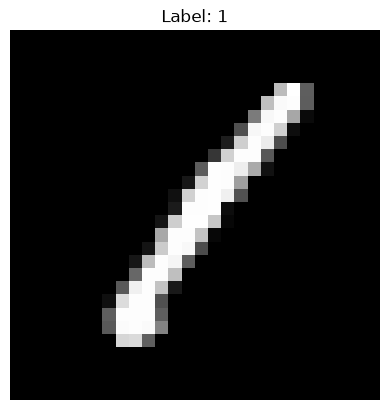

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# 取出第一行数据的真实标签
label = train.loc[0, "label"]

# 取出这一行的 784 个像素值
pixels = train.loc[0, "pixel0":"pixel783"].to_numpy()

# 把一维数组还原成 28×28 的图像
image = pixels.reshape(28, 28)

# 显示图片
plt.imshow(image, cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

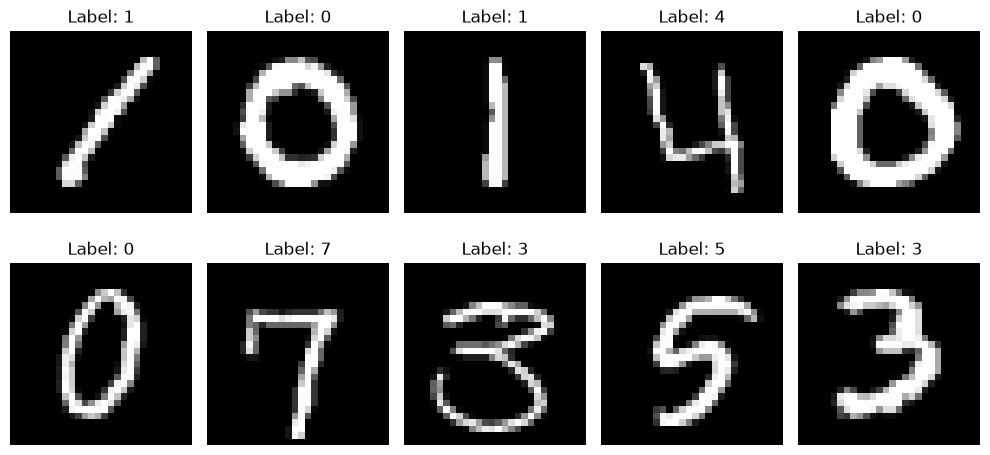

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    pixels = train.iloc[i, 1:].to_numpy().reshape(28, 28)
    label = train.iloc[i, 0]

    ax.imshow(pixels, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
%whos

Variable   Type         Data/Info
---------------------------------
ax         Axes         Axes(0.803,0.0852011;0.182x0.364)
axes       ndarray      2x5: 10 elems, type `object`, 80 bytes
fig        Figure       Figure(1000x500)
i          int          9
image      ndarray      28x28: 784 elems, type `int64`, 6272 bytes
label      int64        3
np         module       <module 'numpy' from 'd:\<...>ges\\numpy\\__init__.py'>
pd         module       <module 'pandas' from 'd:<...>es\\pandas\\__init__.py'>
pixels     ndarray      28x28: 784 elems, type `int64`, 6272 bytes
plt        module       <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
test       DataFrame    Shape: (28000, 784)
torch      module       <module 'torch' from 'd:\<...>ges\\torch\\__init__.py'>
train      DataFrame    Shape: (42000, 785)


In [8]:
from sklearn.model_selection import train_test_split

# 1. 分离标签与像素特征
X = train.drop(columns=["label"])
y = train["label"]

# 2. 划分训练集与验证集
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. 查看划分结果
print("训练集特征：", X_train.shape)
print("验证集特征：", X_val.shape)
print("训练集标签：", y_train.shape)
print("验证集标签：", y_val.shape)

训练集特征： (33600, 784)
验证集特征： (8400, 784)
训练集标签： (33600,)
验证集标签： (8400,)


In [9]:
print("训练集各数字数量：")
print(y_train.value_counts().sort_index())

print("\n验证集各数字数量：")
print(y_val.value_counts().sort_index())

训练集各数字数量：
label
0    3305
1    3747
2    3342
3    3481
4    3258
5    3036
6    3310
7    3521
8    3250
9    3350
Name: count, dtype: int64

验证集各数字数量：
label
0    827
1    937
2    835
3    870
4    814
5    759
6    827
7    880
8    813
9    838
Name: count, dtype: int64


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. 创建模型
model = LogisticRegression(
    max_iter=1000
)

# 2. 只用训练集训练
model.fit(X_train, y_train)

# 3. 分别预测训练集和验证集
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

# 4. 计算准确率
train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)

print(f"训练准确率：{train_acc:.4%}")
print(f"验证准确率：{val_acc:.4%}")

训练准确率：95.5863%
验证准确率：89.6071%


d:\Code\digit-recognizer\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. 像素归一化：将 0~255 缩放到 0~1
X_train_scaled = X_train / 255.0
X_val_scaled = X_val / 255.0

# 2. 创建一个新的逻辑回归模型
model_scaled = LogisticRegression(
    max_iter=2000
)

# 3. 训练模型
model_scaled.fit(X_train_scaled, y_train)

# 4. 分别预测训练集和验证集
train_pred = model_scaled.predict(X_train_scaled)
val_pred = model_scaled.predict(X_val_scaled)

# 5. 计算准确率
train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)

print(f"训练准确率：{train_acc:.4%}")
print(f"验证准确率：{val_acc:.4%}")
print("实际迭代次数：", model_scaled.n_iter_[0])

训练准确率：94.5655%
验证准确率：91.3095%
实际迭代次数： 232


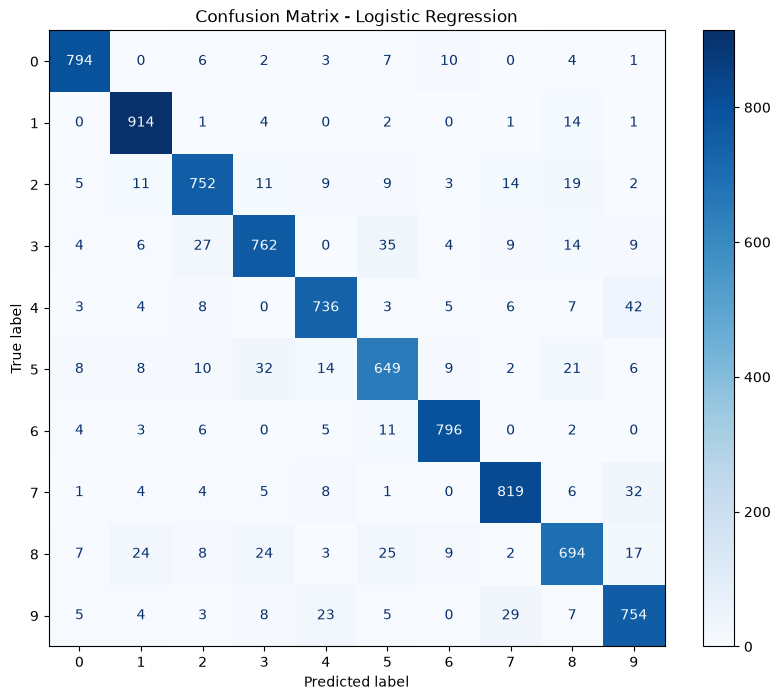

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 预测验证集
val_pred = model_scaled.predict(X_val_scaled)

# 计算混淆矩阵
cm = confusion_matrix(y_val, val_pred)

# 可视化
fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

真实数字 4 被识别成 9 的数量： 42


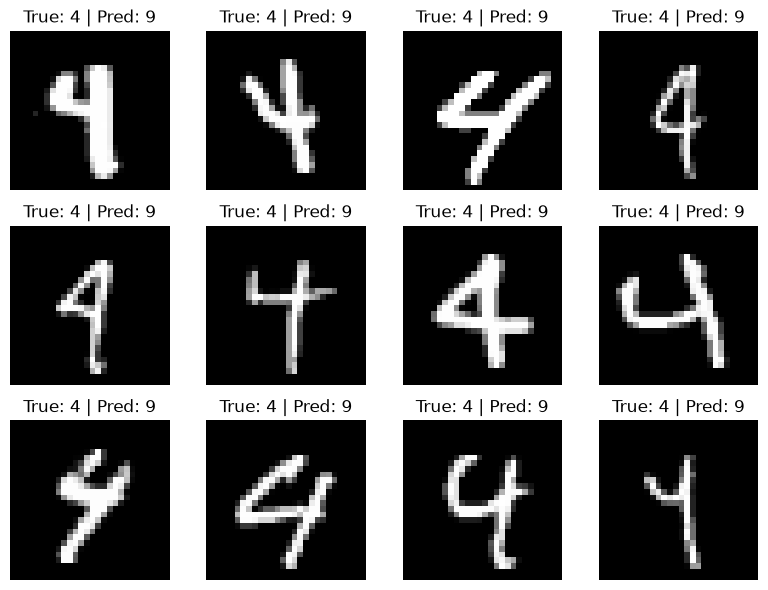

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 找出真实标签为 4、但被预测成 9 的图片
mask = (y_val.to_numpy() == 4) & (val_pred == 9)

# 获取这些图片在验证集中的位置
wrong_indices = np.where(mask)[0]

print("真实数字 4 被识别成 9 的数量：", len(wrong_indices))

# 展示前 12 张错误图片
fig, axes = plt.subplots(3, 4, figsize=(8, 6))

for ax, idx in zip(axes.flat, wrong_indices[:12]):
    image = X_val.iloc[idx].to_numpy().reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"True: 4 | Pred: {val_pred[idx]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# 将像素转换为 float32，并缩放到 0~1
X_train_tensor = torch.tensor(
    X_train.to_numpy(),
    dtype=torch.float32
) / 255.0

X_val_tensor = torch.tensor(
    X_val.to_numpy(),
    dtype=torch.float32
) / 255.0

# 标签转换为 long 类型
y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val.to_numpy(),
    dtype=torch.long
)

print("训练图片：", X_train_tensor.shape)
print("训练标签：", y_train_tensor.shape)
print("验证图片：", X_val_tensor.shape)
print("验证标签：", y_val_tensor.shape)

训练图片： torch.Size([33600, 784])
训练标签： torch.Size([33600])
验证图片： torch.Size([8400, 784])
验证标签： torch.Size([8400])


In [ ]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

print("训练批次数：", len(train_loader))
print("验证批次数：", len(val_loader))

训练批次数： 263
验证批次数： 66


In [16]:
import torch.nn as nn

class DigitMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = DigitMLP()

print(model)

DigitMLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [17]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [18]:
from sklearn.metrics import accuracy_score

epochs = 5

for epoch in range(epochs):
    # ===== 训练阶段 =====
    model.train()

    total_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        # 清除上一批次的梯度
        optimizer.zero_grad()

        # 前向传播
        outputs = model(images)

        # 计算损失
        loss = criterion(outputs, labels)

        # 反向传播
        loss.backward()

        # 更新模型参数
        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = total_loss / train_total
    train_acc = train_correct / train_total

    # ===== 验证阶段 =====
    model.eval()

    val_correct = 0
    val_total = 0
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)

            loss = criterion(outputs, labels)
            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

Epoch [1/5] Train Loss: 0.5335 | Train Acc: 86.22% | Val Loss: 0.2940 | Val Acc: 91.50%
Epoch [2/5] Train Loss: 0.2481 | Train Acc: 92.95% | Val Loss: 0.2271 | Val Acc: 93.43%
Epoch [3/5] Train Loss: 0.1909 | Train Acc: 94.54% | Val Loss: 0.1976 | Val Acc: 94.31%
Epoch [4/5] Train Loss: 0.1544 | Train Acc: 95.69% | Val Loss: 0.1693 | Val Acc: 95.05%
Epoch [5/5] Train Loss: 0.1277 | Train Acc: 96.41% | Val Loss: 0.1506 | Val Acc: 95.64%


In [19]:
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# =========================
# 1. 固定随机种子
# =========================
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# 自动选择 GPU 或 CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("当前设备：", device)


# =========================
# 2. 定义模型
# =========================
class DigitMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


# 重新初始化模型和优化器
model = DigitMLP().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


# =========================
# 3. 训练参数
# =========================
max_epochs = 20
patience = 4
min_delta = 1e-4

best_val_loss = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}


# =========================
# 4. 开始训练
# =========================
for epoch in range(max_epochs):

    # ---- 训练阶段 ----
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total


    # ---- 验证阶段 ----
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total


    # ---- 保存本轮指标 ----
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)


    # ---- 判断是否刷新最佳模型 ----
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())

        # 保存最佳模型参数
        torch.save(
            best_state,
            "best_digit_mlp.pth"
        )

        epochs_without_improvement = 0
        status = "保存最佳模型"
    else:
        epochs_without_improvement += 1
        status = (
            f"验证损失未改善 "
            f"({epochs_without_improvement}/{patience})"
        )


    # ---- 打印本轮结果 ----
    print(
        f"Epoch [{epoch + 1:02d}/{max_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"{status}"
    )


    # ---- 早停 ----
    if epochs_without_improvement >= patience:
        print(f"\n触发早停，停止于第 {epoch + 1} 轮。")
        break


# =========================
# 5. 恢复最佳模型
# =========================
model.load_state_dict(best_state)
model.eval()

print("\n训练结束！")
print("最佳轮次：", best_epoch)
print(f"最佳验证损失：{best_val_loss:.4f}")
print(
    f"最佳轮次验证准确率："
    f"{history['val_acc'][best_epoch - 1]:.2%}"
)
print("最佳模型已保存：best_digit_mlp.pth")

当前设备： cuda
Epoch [01/20] Train Loss: 0.5228 | Train Acc: 86.61% | Val Loss: 0.2856 | Val Acc: 91.62% | 保存最佳模型
Epoch [02/20] Train Loss: 0.2445 | Train Acc: 93.08% | Val Loss: 0.2174 | Val Acc: 93.56% | 保存最佳模型
Epoch [03/20] Train Loss: 0.1870 | Train Acc: 94.68% | Val Loss: 0.1878 | Val Acc: 94.37% | 保存最佳模型
Epoch [04/20] Train Loss: 0.1521 | Train Acc: 95.64% | Val Loss: 0.1696 | Val Acc: 94.80% | 保存最佳模型
Epoch [05/20] Train Loss: 0.1261 | Train Acc: 96.42% | Val Loss: 0.1468 | Val Acc: 95.51% | 保存最佳模型
Epoch [06/20] Train Loss: 0.1062 | Train Acc: 97.00% | Val Loss: 0.1358 | Val Acc: 95.85% | 保存最佳模型
Epoch [07/20] Train Loss: 0.0908 | Train Acc: 97.45% | Val Loss: 0.1254 | Val Acc: 96.14% | 保存最佳模型
Epoch [08/20] Train Loss: 0.0774 | Train Acc: 97.88% | Val Loss: 0.1227 | Val Acc: 96.11% | 保存最佳模型
Epoch [09/20] Train Loss: 0.0669 | Train Acc: 98.15% | Val Loss: 0.1175 | Val Acc: 96.31% | 保存最佳模型
Epoch [10/20] Train Loss: 0.0574 | Train Acc: 98.46% | Val Loss: 0.1080 | Val Acc: 96.67% | 保存最佳模型

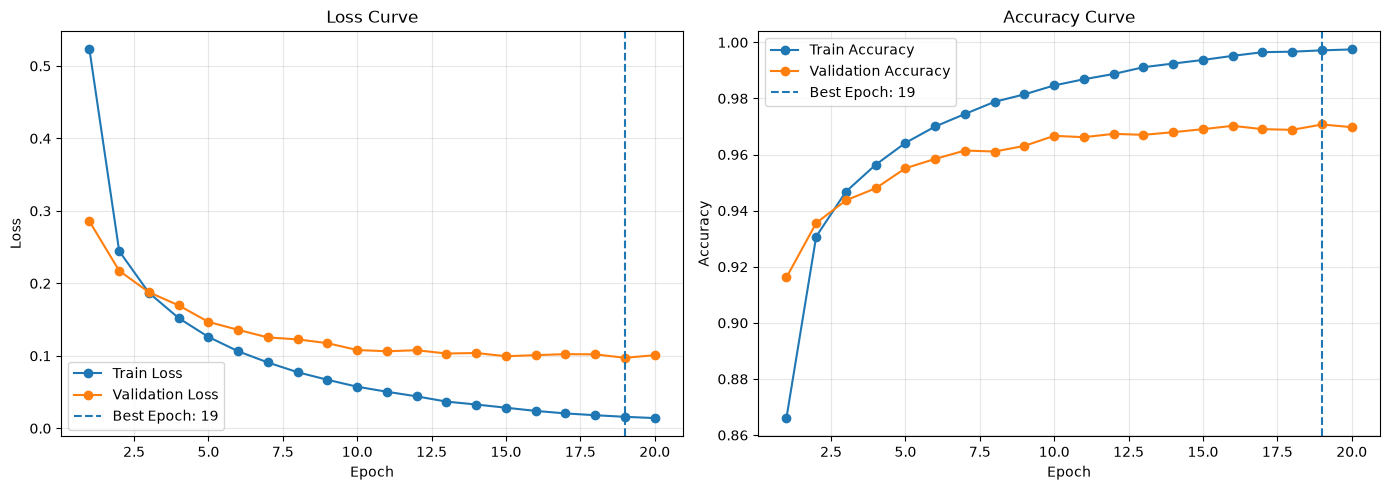

In [20]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 损失曲线
axes[0].plot(
    epochs, history["train_loss"],
    marker="o", label="Train Loss"
)
axes[0].plot(
    epochs, history["val_loss"],
    marker="o", label="Validation Loss"
)
axes[0].axvline(
    best_epoch, linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)
axes[0].set_title("Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 准确率曲线
axes[1].plot(
    epochs, history["train_acc"],
    marker="o", label="Train Accuracy"
)
axes[1].plot(
    epochs, history["val_acc"],
    marker="o", label="Validation Accuracy"
)
axes[1].axvline(
    best_epoch, linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)
axes[1].set_title("Accuracy Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# 从训练集获取一个批次
sample_images, sample_labels = next(iter(train_loader))

# 把图片数据赋值给 x
x = sample_images

print("转换前：", x.shape)

# 转换为 CNN 所需的四维形状
x = x.reshape(-1, 1, 28, 28)

print("转换后：", x.shape)

转换前： torch.Size([128, 784])
转换后： torch.Size([128, 1, 28, 28])


In [22]:
import torch
import torch.nn as nn

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # 输入：1 × 28 × 28
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # 输入：16 × 14 × 14
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        # [N, 784] -> [N, 1, 28, 28]
        x = x.reshape(-1, 1, 28, 28)

        x = self.features(x)
        x = self.classifier(x)

        return x


cnn_model = DigitCNN().to(device)

print(cnn_model)

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [23]:
cnn_model.eval()

with torch.no_grad():
    sample_images, sample_labels = next(iter(train_loader))
    sample_images = sample_images.to(device)

    x = sample_images.reshape(-1, 1, 28, 28)

    print("输入形状：", x.shape)

    x = cnn_model.features[0](x)
    print("第一层卷积：", x.shape)

    x = cnn_model.features[1](x)
    x = cnn_model.features[2](x)
    print("第一次池化：", x.shape)

    x = cnn_model.features[3](x)
    print("第二层卷积：", x.shape)

    x = cnn_model.features[4](x)
    x = cnn_model.features[5](x)
    print("第二次池化：", x.shape)

    x = cnn_model.classifier(x)
    print("最终输出：", x.shape)

输入形状： torch.Size([128, 1, 28, 28])
第一层卷积： torch.Size([128, 16, 28, 28])
第一次池化： torch.Size([128, 16, 14, 14])
第二层卷积： torch.Size([128, 32, 14, 14])
第二次池化： torch.Size([128, 32, 7, 7])
最终输出： torch.Size([128, 10])


In [24]:
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 重新初始化 CNN 和优化器
cnn_model = DigitCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

# 训练配置
max_epochs = 20
patience = 4
min_delta = 1e-4

best_val_loss = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

cnn_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

# 开始训练
for epoch in range(max_epochs):

    # ===== 训练阶段 =====
    cnn_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ===== 验证阶段 =====
    cnn_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # 保存历史指标
    cnn_history["train_loss"].append(train_loss)
    cnn_history["val_loss"].append(val_loss)
    cnn_history["train_acc"].append(train_acc)
    cnn_history["val_acc"].append(val_acc)

    # 判断是否刷新最佳模型
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = copy.deepcopy(cnn_model.state_dict())

        torch.save(best_state, "best_digit_cnn.pth")

        epochs_without_improvement = 0
        status = "保存最佳模型"
    else:
        epochs_without_improvement += 1
        status = (
            f"验证损失未改善 "
            f"({epochs_without_improvement}/{patience})"
        )

    print(
        f"Epoch [{epoch + 1:02d}/{max_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"{status}"
    )

    # 早停
    if epochs_without_improvement >= patience:
        print(f"\n触发早停，停止于第 {epoch + 1} 轮。")
        break

# 恢复最佳模型参数
cnn_model.load_state_dict(best_state)
cnn_model.eval()

print("\nCNN 训练结束！")
print("最佳轮次：", best_epoch)
print(f"最佳验证损失：{best_val_loss:.4f}")
print(
    f"最佳轮次验证准确率："
    f"{cnn_history['val_acc'][best_epoch - 1]:.2%}"
)
print("模型参数已保存至 best_digit_cnn.pth")

Epoch [01/20] Train Loss: 0.4812 | Train Acc: 85.65% | Val Loss: 0.1663 | Val Acc: 94.64% | 保存最佳模型
Epoch [02/20] Train Loss: 0.1169 | Train Acc: 96.51% | Val Loss: 0.0914 | Val Acc: 97.38% | 保存最佳模型
Epoch [03/20] Train Loss: 0.0702 | Train Acc: 97.90% | Val Loss: 0.0713 | Val Acc: 97.83% | 保存最佳模型
Epoch [04/20] Train Loss: 0.0540 | Train Acc: 98.30% | Val Loss: 0.0681 | Val Acc: 97.99% | 保存最佳模型
Epoch [05/20] Train Loss: 0.0422 | Train Acc: 98.68% | Val Loss: 0.0641 | Val Acc: 97.93% | 保存最佳模型
Epoch [06/20] Train Loss: 0.0379 | Train Acc: 98.83% | Val Loss: 0.0567 | Val Acc: 98.49% | 保存最佳模型
Epoch [07/20] Train Loss: 0.0317 | Train Acc: 98.98% | Val Loss: 0.0527 | Val Acc: 98.43% | 保存最佳模型
Epoch [08/20] Train Loss: 0.0263 | Train Acc: 99.18% | Val Loss: 0.0540 | Val Acc: 98.46% | 验证损失未改善 (1/4)
Epoch [09/20] Train Loss: 0.0209 | Train Acc: 99.36% | Val Loss: 0.0547 | Val Acc: 98.48% | 验证损失未改善 (2/4)
Epoch [10/20] Train Loss: 0.0190 | Train Acc: 99.38% | Val Loss: 0.0471 | Val Acc: 98.77% | 保存最

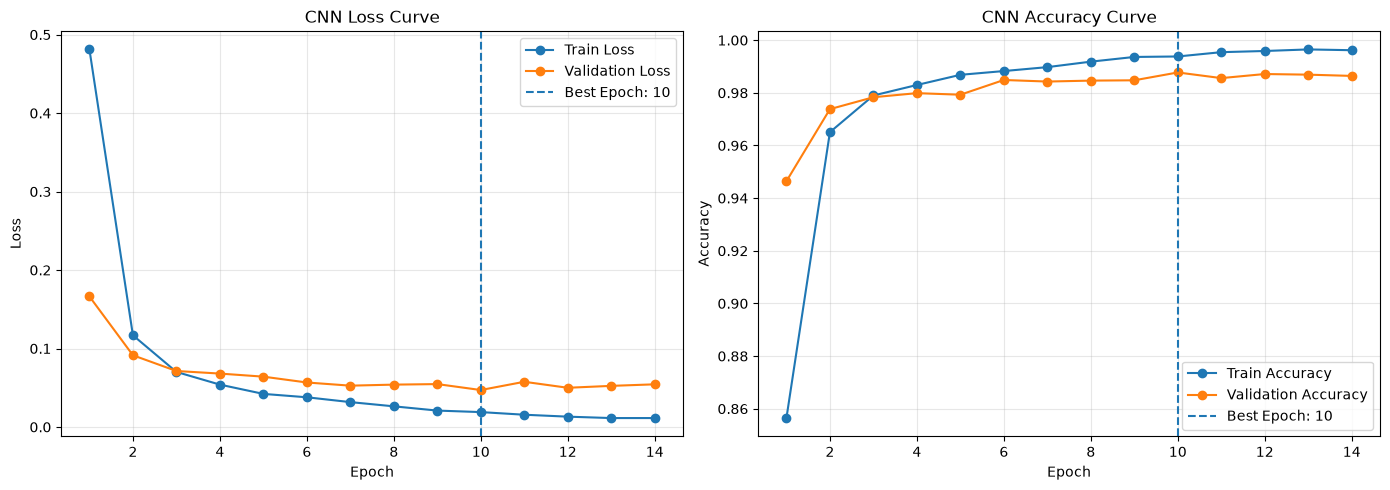

In [25]:
epochs = range(1, len(cnn_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 损失曲线
axes[0].plot(
    epochs, cnn_history["train_loss"],
    marker="o", label="Train Loss"
)
axes[0].plot(
    epochs, cnn_history["val_loss"],
    marker="o", label="Validation Loss"
)
axes[0].axvline(
    best_epoch, linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)
axes[0].set_title("CNN Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 准确率曲线
axes[1].plot(
    epochs, cnn_history["train_acc"],
    marker="o", label="Train Accuracy"
)
axes[1].plot(
    epochs, cnn_history["val_acc"],
    marker="o", label="Validation Accuracy"
)
axes[1].axvline(
    best_epoch, linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)
axes[1].set_title("CNN Accuracy Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()